# Projeto 2 — Sprint 2 | Notebook 1: análise preliminar e teste de hipótese da média

**Tema:** tempo de carregamento de caminhões com grãos (minutos).
**Disciplina:** Estatística e Análise de Dados — 2º semestre de 2026.

Este notebook atende às partes de **média** da Sprint 2:

- Questão 1 — retomada da situação e comparação dos parâmetros antes (Planilha 1, população) e depois (Planilha 2, amostra);
- Questão 2 — teste de hipótese da média para α = 1% e α = 5%, com gráficos das regiões de rejeição e de não rejeição.

O teste da proporção (Questão 3) está no Notebook 2. Os dados originais não são alterados.

## 1. Carregamento e verificação dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

COLUNA = "Tempo de carregamento (min)"
ARQ_ANTES = "planilha-1-antes-intervencao.xlsx"
ARQ_DEPOIS = "planilha-2-depois-intervencao.xlsx"

def localizar(nome):
    """Procura a planilha na pasta dados/ do repositório ou na pasta atual."""
    for pasta in [Path("../../dados"), Path("dados"), Path(".")]:
        if (pasta / nome).exists():
            return pasta / nome
    return None

def carregar(nome):
    caminho = localizar(nome)
    if caminho is None:  # execução no Google Colab sem o repositório
        from google.colab import files
        print(f"Envie o arquivo {nome}")
        enviado = files.upload()
        caminho = next(iter(enviado))
    df = pd.read_excel(caminho)
    if COLUNA not in df.columns:
        raise ValueError(f"Coluna {COLUNA!r} não encontrada em {nome}: {df.columns.tolist()}")
    bruto = df[COLUNA]
    valores = pd.to_numeric(bruto, errors="coerce")
    print(f"{nome}: {len(bruto)} linhas, {int(valores.isna().sum())} valores ausentes/não numéricos")
    return valores.dropna()

antes = carregar(ARQ_ANTES)    # Planilha 1: população de referência (antes da intervenção)
depois = carregar(ARQ_DEPOIS)  # Planilha 2: amostra após a intervenção

assert len(antes) == 300 and len(depois) == 100, "Tamanhos diferentes dos registrados na Sprint 1"

PASTA_FIG = Path("../../resultados/figuras")
PASTA_TAB = Path("../../resultados/tabelas")
if not PASTA_FIG.parent.exists():
    PASTA_FIG, PASTA_TAB = Path("figuras"), Path("tabelas")
PASTA_FIG.mkdir(parents=True, exist_ok=True)
PASTA_TAB.mkdir(parents=True, exist_ok=True)

def br(x, casas=4):
    """Formata número com vírgula decimal e sinal de menos tipográfico."""
    return f"{x:.{casas}f}".replace(".", ",").replace("-", "−")


planilha-1-antes-intervencao.xlsx: 300 linhas, 0 valores ausentes/não numéricos
planilha-2-depois-intervencao.xlsx: 100 linhas, 0 valores ausentes/não numéricos


In [2]:
print("Coluna analisada:", COLUNA, "| unidade: minutos")
print(f"Planilha 1 (antes): n = {len(antes)} | mínimo = {antes.min()} | máximo = {antes.max()}")
print(f"Planilha 2 (depois): n = {len(depois)} | mínimo = {depois.min()} | máximo = {depois.max()}")

Coluna analisada: Tempo de carregamento (min) | unidade: minutos
Planilha 1 (antes): n = 300 | mínimo = 22.3 | máximo = 43.5
Planilha 2 (depois): n = 100 | mínimo = 18.6 | máximo = 38.5


## 2. Questão 1 — parâmetros na população (Planilha 1) e na amostra (Planilha 2)

A proporção usa o intervalo-alvo **[20, 30] min**, ligado ao objetivo da Sprint 1 (Questão 7.1: aumentar a proporção de carregamentos concluídos em até 30 minutos).

- Na população, a proporção de referência **p** é a probabilidade de um tempo estar em [20, 30] pelo **modelo normal** ajustado à Planilha 1, mesmo método da Questão 5 da Sprint 1. A Questão 5 original usou [20, 43] e foi corrigida para o mesmo intervalo da Questão 7.4, como pede a orientação da Sprint 2 (ver Notebook 2).
- Na amostra, **p̂** é a frequência observada em [20, 30] na Planilha 2 (Questão 7.4(b) da Sprint 1).

In [3]:
A, B = 20, 30

mu_pop = antes.mean()
sigma_pop = antes.std(ddof=1)          # desvio-padrão registrado na Sprint 1 (Questão 3)
p_pop_modelo = stats.norm.cdf(B, mu_pop, sigma_pop) - stats.norm.cdf(A, mu_pop, sigma_pop)
p_pop_obs = antes.between(A, B, inclusive="both").mean()

xbarra = depois.mean()
s_amostra = depois.std(ddof=1)
k_amostra = int(depois.between(A, B, inclusive="both").sum())
p_chapeu = k_amostra / len(depois)

tabela_q1 = pd.DataFrame({
    "Parâmetro": ["n (observações)", "Média (min)", "Desvio-padrão (min)", "Mediana (min)",
                  "Proporção em [20, 30] — modelo normal (Q5 corrigida)",
                  "Proporção em [20, 30] — frequência observada"],
    "Planilha 1 — antes (população)": [len(antes), mu_pop, sigma_pop, antes.median(), p_pop_modelo, p_pop_obs],
    "Planilha 2 — depois (amostra)": [len(depois), xbarra, s_amostra, depois.median(), np.nan, p_chapeu],
})
tabela_q1.to_csv(PASTA_TAB / "q1_parametros.csv", index=False, decimal=",", sep=";")
tabela_q1.round(4).astype(object).fillna("—")

,Parâmetro,Planilha 1 — antes (população),Planilha 2 — depois (amostra)
0,n (observações),300.0,100.0
1,Média (min),31.8867,29.31
2,Desvio-padrão (min),3.8181,3.8184
3,Mediana (min),31.8,29.3
4,"Proporção em [20, 30] — modelo normal (Q5 corr...",0.3097,—
5,"Proporção em [20, 30] — frequência observada",0.3233,0.57


In [4]:
dif = xbarra - mu_pop
print(f"Variação da média: {br(dif, 4)} min ({br(100*dif/mu_pop, 2)}% da média inicial)")
print(f"Proporção em [20, 30]: população (modelo) = {br(100*p_pop_modelo, 2)}% | "
      f"população (observada) = {br(100*p_pop_obs, 2)}% | amostra = {br(100*p_chapeu, 2)}%")
print(f"Aumento em relação ao modelo: {br(100*(p_chapeu - p_pop_modelo), 2)} pontos percentuais")

Variação da média: −2,5767 min (−8,08% da média inicial)
Proporção em [20, 30]: população (modelo) = 30,97% | população (observada) = 32,33% | amostra = 57,00%
Aumento em relação ao modelo: 26,03 pontos percentuais


**Leitura preliminar (Questão 1):** a média caiu de 31,89 min para 29,31 min (−2,58 min; −8,08%) e a proporção de carregamentos em [20, 30] min subiu de 30,97% (modelo; 32,33% observados) para 57%. Os dois critérios apontam na direção do objetivo e são **indícios descritivos** de eficácia. Isoladamente, não mostram se a diferença poderia ser explicada só pela variação natural de uma amostra de 100 carregamentos. Por isso fazemos os testes de hipótese.

## 3. Questão 2a — hipóteses do teste da média

**Pergunta testável:** o tempo médio de carregamento após a padronização da preparação é **menor** que 31,8867 min, a média da Planilha 1?

- H₀: μ = 31,8867 min (o tempo médio após a intervenção é igual ao de referência);
- H₁: μ < 31,8867 min (o tempo médio após a intervenção é menor).

O teste é **unilateral à esquerda**, porque o objetivo é reduzir o tempo. H₀ contém a igualdade, conforme a aula de testes de hipótese. As hipóteses foram definidas antes de calcular a estatística.

## 4. Questão 2b — estatística de teste

Fórmula da aula (valor de referência para a média):

$$z_{calc} = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}}$$

- μ₀ = média da Planilha 1, tratada como população (orientação da Sprint 2);
- σ = desvio-padrão da Planilha 1 (3,8181 min, valor registrado na Sprint 1). Não há um σ populacional fornecido pela empresa. Usamos o da Planilha 1 porque a orientação trata essa planilha como população. O desvio da Planilha 2 (3,8184 min) é praticamente igual, o que sustenta a suposição de dispersão constante;
- n = 100 > 30: pelo Teorema do Limite Central, a média amostral tem distribuição aproximadamente normal.

In [5]:
mu0 = mu_pop
sigma = sigma_pop
n = len(depois)

erro_padrao = sigma / np.sqrt(n)
z_calc = (xbarra - mu0) / erro_padrao
p_valor = stats.norm.cdf(z_calc)   # unilateral à esquerda

print(f"x̄ = {br(xbarra)} min | μ0 = {br(mu0)} min | σ = {br(sigma)} min | n = {n}")
print(f"σ/√n = {br(sigma)}/√{n} = {br(erro_padrao)} min")
print(f"z_calc = ({br(xbarra)} − {br(mu0)}) / {br(erro_padrao)} = {br(z_calc)}")
print(f"p-valor (complementar) = P(Z ≤ z_calc) = {p_valor:.2e}")

x̄ = 29,3100 min | μ0 = 31,8867 min | σ = 3,8181 min | n = 100
σ/√n = 3,8181/√100 = 0,3818 min
z_calc = (29,3100 − 31,8867) / 0,3818 = −6,7485
p-valor (complementar) = P(Z ≤ z_calc) = 7.47e-12


In [6]:
linhas = []
for alpha in (0.05, 0.01):
    z_crit = stats.norm.ppf(alpha)
    xbarra_crit = mu0 + z_crit * erro_padrao
    rejeita = z_calc <= z_crit
    linhas.append({
        "α": f"{int(alpha*100)}%",
        "z crítico": round(z_crit, 4),
        "Região de rejeição": f"z ≤ {br(z_crit, 3)}  (x̄ ≤ {br(xbarra_crit, 2)} min)",
        "Região de não rejeição": f"z > {br(z_crit, 3)}  (x̄ > {br(xbarra_crit, 2)} min)",
        "z calculado": round(z_calc, 4),
        "Decisão": "Rejeitar H0" if rejeita else "Não rejeitar H0",
    })
resultado_media = pd.DataFrame(linhas)
resultado_media.to_csv(PASTA_TAB / "q2_teste_media.csv", index=False, sep=";")
resultado_media

,α,z crítico,Região de rejeição,Região de não rejeição,z calculado,Decisão
0,5%,-1.6449,"z ≤ −1,645 (x̄ ≤ 31,26 min)","z > −1,645 (x̄ > 31,26 min)",-6.7485,Rejeitar H0
1,1%,-2.3263,"z ≤ −2,326 (x̄ ≤ 31,00 min)","z > −2,326 (x̄ > 31,00 min)",-6.7485,Rejeitar H0


### Gráficos das regiões de rejeição e de não rejeição (α = 5% e α = 1%)

In [7]:
# Cores: azul = não rejeição; vermelho hachurado = rejeição (rótulos diretos, não só cor)
COR_NAO_REJ, COR_REJ = "#257de0", "#ec4647"
TINTA, TINTA_2 = "#191919", "#666666"

def grafico_regioes(z_calc, z_crit, cauda, alpha, titulo, arquivo, xlim):
    x = np.linspace(xlim[0], xlim[1], 3000)
    y = stats.norm.pdf(x)
    rej = x <= z_crit if cauda == "esquerda" else x >= z_crit

    fig, ax = plt.subplots(figsize=(9, 4.6))
    ax.fill_between(x, 0, y, where=~rej, color=COR_NAO_REJ, alpha=0.20, linewidth=0)
    ax.fill_between(x, 0, y, where=rej, facecolor=COR_REJ, alpha=0.40,
                    hatch="///", edgecolor=COR_REJ, linewidth=0)
    ax.plot(x, y, color=TINTA, lw=2)

    # valor crítico
    ax.axvline(z_crit, color=TINTA_2, ls="--", lw=1.5)
    ax.text(z_crit, 0.44, f"z crítico = {br(z_crit, 3)}", ha="center", va="center",
            color=TINTA_2, fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none"))

    # z calculado (rótulo sempre à direita da linha, longe do eixo y)
    ax.axvline(z_calc, color=TINTA, lw=2)
    ax.plot([z_calc], [0], "o", ms=9, color=TINTA, clip_on=False, zorder=5)
    ax.text(z_calc + 0.15, 0.32, f"z calculado\n= {br(z_calc, 4)}", ha="left", va="center",
            color=TINTA, fontsize=10, fontweight="bold")

    # rótulos das regiões
    ax.text(0, 0.12, "Região de\nnão rejeição de H₀", ha="center", va="center",
            color=TINTA, fontsize=10)
    x_rej = z_crit - 2.1 if cauda == "esquerda" else z_crit + 1.9
    ax.annotate(f"Região de rejeição de H₀\n(área = α = {int(alpha*100)}%)",
                xy=(z_crit + (-0.25 if cauda == "esquerda" else 0.25), 0.01),
                xytext=(x_rej, 0.20), ha="center", fontsize=10, color=TINTA,
                arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=1))

    ax.set_xlim(*xlim); ax.set_ylim(0, 0.47)
    ax.set_xlabel("z (distribuição normal padrão sob H₀)", color=TINTA_2)
    ax.set_ylabel("Densidade", color=TINTA_2)
    ax.set_title(titulo, loc="left", fontsize=12, color=TINTA)
    for lado_ax in ("top", "right"):
        ax.spines[lado_ax].set_visible(False)
    ax.spines["left"].set_color(TINTA_2); ax.spines["bottom"].set_color(TINTA_2)
    ax.tick_params(colors=TINTA_2)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(PASTA_FIG / arquivo, dpi=200)
    plt.show()


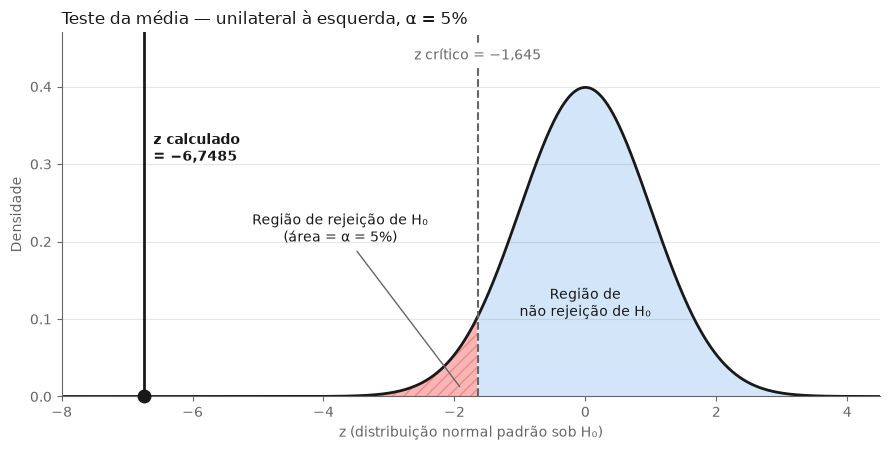

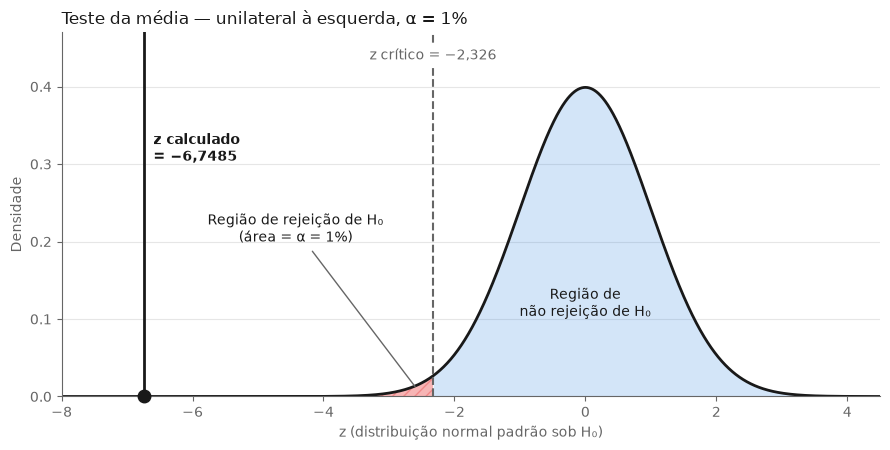

In [8]:
for alpha in (0.05, 0.01):
    grafico_regioes(
        z_calc=z_calc, z_crit=stats.norm.ppf(alpha), cauda="esquerda", alpha=alpha,
        titulo=f"Teste da média — unilateral à esquerda, α = {int(alpha*100)}%",
        arquivo=f"teste_media_alfa_{int(alpha*100):02d}.png", xlim=(-8, 4.5))

### Decisão e conclusão

- **α = 5%:** z crítico = −1,645. Região de rejeição: z ≤ −1,645. Como z_calc = −6,7485 está na região de rejeição, **rejeita-se H₀**. Ao nível de 5%, há evidência estatística de que o tempo médio de carregamento após a padronização é menor que 31,89 min.
- **α = 1%:** z crítico = −2,326. Região de rejeição: z ≤ −2,326. Como z_calc = −6,7485 também está na região de rejeição, **rejeita-se H₀**. Mesmo com o critério mais exigente, há evidência de que o tempo médio após a intervenção é menor que 31,89 min.

Em minutos: a média amostral precisaria ficar abaixo de 31,26 min (5%) ou 31,00 min (1%) para rejeitar H₀. O valor observado, 29,31 min, está bem abaixo dos dois limites.

## 5. Questão 2c — comparação com a análise preliminar

A conclusão do teste **coincide** com a análise preliminar da Questão 1. A redução observada (31,89 → 29,31 min) é grande demais para ser atribuída apenas à variação amostral: z_calc = −6,75 está muito além dos valores críticos, e o p-valor é da ordem de 10⁻¹¹.

O teste confirma que a **média diminuiu**. Ele não prova que a padronização foi a **causa** da redução. A comparação antes/depois é observacional: a coleta da Planilha 2 ocorreu em outro período e pode refletir outros fatores (safra, equipe, fila, equipamentos). O teste também supõe que os 100 carregamentos são uma amostra representativa e independente, e que o desvio-padrão se manteve após a intervenção.

## 6. Análise de sensibilidade (complementar)

In [9]:
sigma_ddof0 = antes.std(ddof=0)
z_ddof0 = (xbarra - mu0) / (sigma_ddof0 / np.sqrt(n))
print(f"Com σ populacional (divisor N): σ = {br(sigma_ddof0)} → z = {br(z_ddof0)}")
print(f"Com o desvio da própria amostra: s = {br(s_amostra)} → z = {br((xbarra - mu0)/(s_amostra/np.sqrt(n)))}")
print("Em todos os casos z ≤ −2,326: a decisão não muda para α = 1% nem para α = 5%.")

Com σ populacional (divisor N): σ = 3,8117 → z = −6,7598
Com o desvio da própria amostra: s = 3,8184 → z = −6,7480
Em todos os casos z ≤ −2,326: a decisão não muda para α = 1% nem para α = 5%.
